# Apprendre l'allocation de Markowitz avec un réseau de neurones

**Projet 4 — M2 ISF, Gestion des risques.** Peut-on apprendre, à partir de l'information disponible à la date $t$, le portefeuille qui *sera* optimal sur les 63 jours suivants ?

| | Partie | Durée |
|---|---|---|
| 1 | Données, features et cible | 3 min |
| 2 | Protocole commun (validation croisée, métriques) et référence k-NN | 3 min |
| 3 | Trois familles de réseaux : MLP, U-Net, récurrents | 5 min |
| 4 | Backtest, interprétation (SHAP) et conclusion | 4 min |

**Principe du notebook : tout est commun.** Un seul chargement des données, une seule normalisation, une seule boucle d'entraînement, une seule validation croisée et une seule fonction d'évaluation, utilisés par tous les modèles. Seule l'architecture change.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.covariance import LedoitWolf

DATA, RES, N = Path("data/processed/N63_wmax1"), Path("synthesis/resultats"), 63    # N : horizon de la cible, en jours
RES.mkdir(parents=True, exist_ok=True)
RERUN = False       # False : relit les résultats déjà calculés dans RES ; True : relance tous les entraînements

## 1. Données, features et cible

**Univers** : 15 actions du CAC 40 (tous secteurs) + un actif **CASH** rémunéré à l'Euribor 3 mois, en données quotidiennes de 2005 à 2025 (Yahoo Finance, FRED, BCE). Le jeu de données est produit une fois pour toute l'équipe par `data_generation/build_dataset.py`.

**Features $X_t$ : 160 variables, toutes calculées sur des fenêtres qui finissent en $t$** (aucune information future).

| Famille | Variables | Nombre |
|---|---|---|
| Par action (×15) | momentum 5, 21, 63, 126, 252 j ; volatilité 21 et 63 j ; volatilité baissière ; drawdown 1 an ; corrélation au CAC | 150 |
| Structure du marché | 3 premières valeurs propres de la matrice de corrélation ; momentum et volatilité du CAC | 5 |
| Macro | VIX et sa variation, pente des taux US, spread de crédit, Euribor 3M | 5 |

**Contrôle qualité** : un test automatique sur les prix (cours figés ou arrondis) nous a fait remplacer AXA, dont l'historique Yahoo était arrondi à l'euro avant 2008, par Société Générale.

In [2]:
read = lambda f: pd.read_csv(f, index_col=0, parse_dates=True)
X, Y, R_fwd, meta, rets = (read(DATA / f"{f}.csv") for f in ["X", "Y", "R_fwd", "meta", "returns"])
ASSETS, TICKERS = list(Y.columns), list(Y.columns[:-1])
Yn = Y.to_numpy()
pos = rets.index.get_indexer(X.index)                 # position de chaque date t dans le calendrier de bourse

# rendements quotidiens des 16 actifs : le CASH rapporte l'Euribor 3M connu la veille
px = read("data/raw/prices.csv").dropna(how="all").ffill(limit=2).dropna(how="any")
macro = read("data/raw/macro.csv")
macro = macro.reindex(px.index.union(macro.index)).ffill().reindex(px.index).shift(1)
rf_day = (macro["EURIBOR3M"] / 100 / 252).reindex(rets.index).fillna(0).to_numpy()
R_day = np.c_[rets.to_numpy(), rf_day]

print(f"X {X.shape} | Y {Y.shape} | {X.index[0].date()} → {X.index[-1].date()}")
print(f"Avant 2020 : {(X.index < '2020').sum()} dates, soit seulement ≈ {(X.index < '2020').sum() // N} trimestres sans chevauchement")

X (5082, 160) | Y (5082, 16) | 2005-11-21 → 2025-09-30
Avant 2020 : 3608 dates, soit seulement ≈ 57 trimestres sans chevauchement


### La cible : l'oracle de Markowitz

Pour chaque date $t$, la cible $Y_t$ est le portefeuille **long-only de Sharpe maximal sur les 63 jours suivants** ($t+1$ à $t+63$) :

$$Y_t=\arg\max_{w\ge 0,\ \sum w=1}\ \frac{w^\top\mu}{\sqrt{w^\top\Sigma\,w}}\qquad \mu:\ \text{rendement moyen en excès du CASH},\quad \Sigma:\ \text{covariance (Ledoit-Wolf)}$$

Si aucune action ne bat le taux sans risque sur la période, l'oracle vaut 100 % CASH. C'est un **oracle** : il connaît le futur. Le modèle doit s'en approcher avec la seule information disponible en $t$.

Écart maximal avec Y.csv le 2015-06-01 : 0.0000
L'oracle détient en moyenne 2.9 actifs effectifs (sur 16), est 100 % CASH 2.4% du temps et change 86% du portefeuille d'un trimestre au suivant.


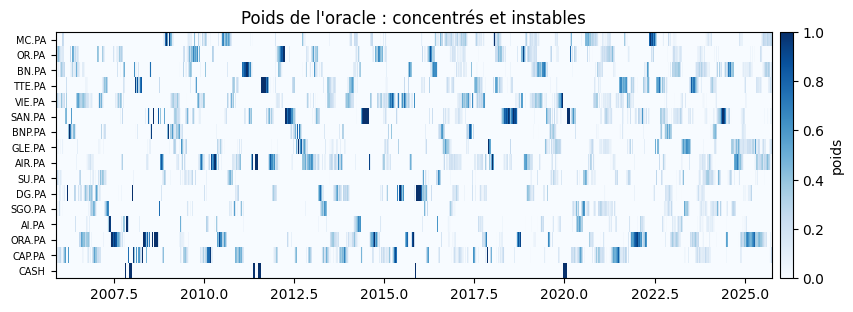

In [3]:
def max_sharpe(win, rf_win):
    # Portefeuille long-only de Sharpe maximal sur une fenêtre de rendements quotidiens (jours × 15 actions).
    mu = (win - rf_win[:, None]).mean(0) * 252
    if mu.max() <= 0:                                           # aucune action ne bat le CASH
        return np.r_[np.zeros(15), 1.0]
    S = LedoitWolf().fit(win).covariance_ * 252
    y0 = np.eye(15)[mu.argmax()] / mu.max()                     # point de départ admissible
    res = minimize(lambda y: y @ S @ y, y0, jac=lambda y: 2 * S @ y, bounds=[(0, None)] * 15, method="SLSQP",
                   constraints={"type": "eq", "fun": lambda y: mu @ y - 1, "jac": lambda y: mu})   # min variance à rendement fixé
    return np.r_[res.x / res.x.sum(), 0.0]

# Vérification : on recalcule la cible d'une date à partir des 63 jours qui la suivent
t = X.index.get_loc("2015-06-01"); p = pos[t]
w = max_sharpe(R_day[p + 1:p + N + 1, :15], rf_day[p + 1:p + N + 1])
print(f"Écart maximal avec Y.csv le {X.index[t].date()} : {np.abs(w - Yn[t]).max():.4f}")

print(f"L'oracle détient en moyenne {(1 / (Yn ** 2).sum(1)).mean():.1f} actifs effectifs (sur 16), "
      f"est 100 % CASH {(Yn[:, -1] == 1).mean():.1%} du temps "
      f"et change {np.abs(Yn[N:] - Yn[:-N]).sum(1).mean() / 2:.0%} du portefeuille d'un trimestre au suivant.")

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(Yn.T, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest",
               extent=[X.index[0].year + X.index[0].dayofyear / 365, X.index[-1].year + X.index[-1].dayofyear / 365, 16, 0])
ax.set_yticks(np.arange(16) + 0.5, ASSETS, fontsize=7); ax.set_title("Poids de l'oracle : concentrés et instables")
fig.colorbar(im, ax=ax, label="poids", pad=0.01); plt.show()

### Un seul prétraitement pour tous les modèles

Chaque famille de modèles lit la même information sous une forme différente. Toutes les entrées sont construites ici, et **normalisées par une seule fonction, avec les statistiques du train uniquement** (recalculées à chaque pli de validation croisée, pour ne jamais utiliser le futur).

| Entrée | Forme | Utilisée par |
|---|---|---|
| `tab` : les 160 features | (dates, 160) | k-NN, MLP |
| `seq_j` : 60 rendements journaliers des 15 actions | (dates, 60, 15) | U-Net, LSTM global |
| `seq_h` : 52 rendements hebdomadaires par action (canal 1) + ceux du CAC (canal 2) | (dates, 15, 52, 2) | LSTM partagé, Transformer |

In [4]:
logr, log_cac = np.log1p(rets.to_numpy()), np.log1p(px["^FCHI"].pct_change().iloc[1:].to_numpy())

def weekly(lr, n_weeks=52, step=5):
    # rendements log hebdomadaires glissants, la dernière semaine finissant en t
    C = np.concatenate([np.zeros((1,) + lr.shape[1:]), lr.cumsum(axis=0)])
    ends = pos[:, None] + 1 - step * np.arange(n_weeks)[::-1]            # (dates, 52) : fin de chaque semaine
    ok = (ends >= step).reshape(ends.shape + (1,) * (lr.ndim - 1))       # semaines avant le début de l'historique : 0
    return (C[ends] - C[ends - step]) * ok

RAW = {"tab": X.to_numpy(),
       "seq_j": np.stack([logr[i - 59:i + 1] for i in pos]),
       "seq_h": np.stack([weekly(logr).transpose(0, 2, 1), np.repeat(weekly(log_cac)[:, None, :], 15, axis=1)], axis=-1)}
STAT_AXES = {"tab": 0, "seq_j": None, "seq_h": (0, 1, 2)}     # features : par colonne ; séquences : une seule échelle par canal

def prepare(names, tr_i):
    # Entrées normalisées avec les statistiques des dates d'entraînement tr_i uniquement.
    out = []
    for n in names:
        a, ax = RAW[n], STAT_AXES[n]
        mean = a[tr_i].mean(axis=ax) if n == "tab" else 0      # les rendements sont déjà centrés : on ne change que l'échelle
        out.append(((a - mean) / a[tr_i].std(axis=ax)).astype(np.float32))
    return out

print({n: a.shape for n, a in RAW.items()})

{'tab': (5082, 160), 'seq_j': (5082, 60, 15), 'seq_h': (5082, 15, 52, 2)}


## 2. Protocole commun

Les cibles de deux jours voisins se chevauchent sur 62 jours : nos ~3 500 dates d'entraînement ne valent qu'une **cinquantaine de trimestres indépendants**. Le protocole est donc fixé à l'avance et identique pour tous les modèles.

**A. Sélection (2006–2019) : validation croisée *walk-forward* à 4 plis.** On entraîne sur tout le passé et on valide sur les 2 années suivantes (2012–13, 2014–15, 2016–17, 2018–19). **Purge** : une date n'entre dans le train que si sa cible se termine avant le début de la validation.

**B. Évaluation finale (2020–2025), une seule fois.** La configuration retenue est réentraînée sur 2006–2019, pendant le nombre d'époques trouvé en validation croisée, puis backtestée sur le test.

**Une seule fonction d'évaluation**, pour les modèles comme pour les références :
- **entropie croisée** avec l'oracle : la qualité de l'imitation (c'est aussi la perte d'entraînement) ;
- **backtest quotidien** : on achète les poids prédits, on les laisse dériver avec les prix, on rééquilibre tous les 63 jours avec **0,1 % de frais** sur les montants échangés. Comme le résultat dépend du jour de départ, on simule les 63 calendriers possibles et on fait la moyenne. On en tire le **Sharpe** (en excès du CASH ; `sharpe_std` mesure sa sensibilité au jour de départ), le rendement, la perte maximale et le **turnover** (part du portefeuille échangée par an) ;
- **nombre effectif d'actifs** $1/\sum_i w_i^2$ : la concentration du portefeuille.

**Les périodes.** Pour chaque période, on sépare les dates d'entraînement et les dates d'évaluation. Purge : une date n'entre dans l'entraînement que si ses 63 jours futurs se terminent avant le début de l'évaluation.

In [5]:
label_end = pd.to_datetime(meta["label_end"])      # dernier jour des 63 jours futurs utilisés par Y_t

def purged_train(before):
    """Dates depuis 2006 dont la cible est entièrement connue avant `before` (purge)."""
    garder = (X.index >= "2006-01-01") & (label_end < pd.Timestamp(before))
    return np.flatnonzero(garder.to_numpy())

# 4 validations de 2 ans : on entraîne sur tout le passé, on évalue sur les 2 années suivantes
FOLDS = {}
for y0 in [2012, 2014, 2016, 2018]:
    garder = (X.index >= f"{y0}-01-01") & (label_end < pd.Timestamp(f"{y0 + 2}-01-01"))
    FOLDS[f"{y0}-{y0 + 1}"] = (purged_train(f"{y0}-01-01"), np.flatnonzero(garder.to_numpy()))

# Test final : entraînement sur 2006–2019, évaluation sur 2020–2025
FINAL = (purged_train("2020-01-01"), np.flatnonzero(meta["split"].to_numpy() == "test"))

for name, (tr, va) in {**FOLDS, "test final": FINAL}.items():
    print(f"{name:10s} : train {len(tr):4d} dates (→ {X.index[tr[-1]].date()}) | "
          f"évaluation {len(va):4d} dates ({X.index[va[0]].date()} → {X.index[va[-1]].date()})")

2012-2013  : train 1472 dates (→ 2011-10-03) | évaluation  446 dates (2012-01-02 → 2013-10-01)
2014-2015  : train 1981 dates (→ 2013-10-01) | évaluation  448 dates (2014-01-02 → 2015-10-01)
2016-2017  : train 2492 dates (→ 2015-10-01) | évaluation  449 dates (2016-01-04 → 2017-09-29)
2018-2019  : train 3004 dates (→ 2017-09-29) | évaluation  448 dates (2018-01-02 → 2019-10-02)
test final : train 3515 dates (→ 2019-10-02) | évaluation 1474 dates (2020-01-02 → 2025-09-30)


**Le juge.** On simule d'abord **un** portefeuille : on achète les poids prédits, ils dérivent avec les prix, et on revient aux nouveaux poids prédits tous les 63 jours (0,1 % de frais). Le résultat dépend du jour du premier rééquilibrage : on simule les 63 possibilités et on fait la moyenne.

In [6]:
def simuler_un_calendrier(W, R_lendemain, decalage, reb=N, cost=1e-3):
    """UN portefeuille : premier rééquilibrage au jour `decalage`, puis tous les `reb` jours."""
    w = W[0].copy()
    rendements, echange_total = [], 0.0
    for d in range(len(W)):
        echange = 0.0
        if d > 0 and d % reb == decalage:                  # jour de rééquilibrage
            echange = np.abs(W[d] - w).sum()               # part du portefeuille vendue + achetée
            w = W[d].copy()
        g = w @ (1 + R_lendemain[d])                       # valeur le lendemain, pour 1 €
        rendements.append(g * (1 - cost * echange) - 1)    # rendement du jour, net de frais
        w = w * (1 + R_lendemain[d]) / g                   # les poids dérivent avec les prix
        echange_total += echange
    return np.array(rendements), echange_total

def evaluate(W, i, reb=N, cost=1e-3):
    """Moyenne des mesures sur les 63 calendriers. W : poids décidés à la clôture de chaque date de i."""
    R_lendemain, rf = R_day[pos[i] + 1], rf_day[pos[i] + 1]   # rendements du jour suivant chaque décision

    # 1. les 63 simulations (une colonne par calendrier)
    sims = [simuler_un_calendrier(W, R_lendemain, k, reb, cost) for k in range(reb)]
    daily = np.column_stack([r for r, _ in sims])
    traded = np.array([e for _, e in sims])

    # 2. mesures de chaque calendrier
    wealth, years = (1 + daily).cumprod(0), len(i) / 252
    sharpe = (daily - rf[:, None]).mean(0) / daily.std(0) * np.sqrt(252)

    # 3. moyenne sur les calendriers
    stats = {"ce": -(Yn[i] * np.log(W + 1e-8)).sum(1).mean(),          # écart avec l'oracle
             "sharpe": sharpe.mean(), "sharpe_std": sharpe.std(),        # + sensibilité au calendrier
             "rdt_ann": (wealth[-1] ** (1 / years) - 1).mean(),
             "perte_max": (wealth / np.maximum.accumulate(wealth) - 1).min(0).mean(),
             "turnover_an": traded.mean() / years,
             "n_eff": (1 / (W ** 2).sum(1)).mean()}                     # nombre effectif d'actifs
    return stats, pd.Series(wealth.mean(1), index=X.index[i])

**Références sur les 4 plis.** Deux portefeuilles qui n'utilisent aucune feature fixent les seuils à battre : l'**équipondéré** (1/15 par action) pour le Sharpe, et la **moyenne des cibles du train** pour l'entropie croisée (un modèle qui ne fait pas mieux n'a rien appris au-delà de la répartition moyenne). L'**oracle** donne le plafond.

In [7]:
# Portefeuille équipondéré : 1/15 sur chaque action, rien en CASH
EW = np.r_[np.full(15, 1 / 15), 0.0]

def references(tr_i, i):
    """Les trois références, sous forme de poids pour chaque date de i (aucune n'utilise les features)."""
    n = len(i)
    return {"Oracle": Yn[i],                                              # le plafond : connaît le futur
            "Équipondéré": np.tile(EW, (n, 1)),                           # même portefeuille chaque jour
            "Moyenne des cibles du train": np.tile(Yn[tr_i].mean(0), (n, 1))}   # allocation moyenne de l'oracle sur le train

# On évalue chaque référence sur chacun des 4 plis, puis on fait la moyenne des 4 plis
lignes = []
for pli, (tr, va) in FOLDS.items():
    for strategie, W in references(tr, va).items():
        mesures, _ = evaluate(W, va)
        lignes.append({"stratégie": strategie, "pli": pli, **mesures})

ref = pd.DataFrame(lignes)
REF_CV = ref.groupby("stratégie", sort=False).mean(numeric_only=True)
REF_CV.round(3)

,ce,sharpe,sharpe_std,rdt_ann,perte_max,turnover_an,n_eff
stratégie,,,,,,,
Oracle,1.044,3.023,0.187,0.762,-0.098,6.588,2.904
Équipondéré,2.726,0.857,0.008,0.156,-0.153,0.242,15.000
Moyenne des cibles du train,2.721,0.898,0.008,0.149,-0.139,0.245,13.446


### Une boucle d'entraînement et une validation croisée pour tous les modèles

- **Perte** : entropie croisée $-\sum_i Y_i\log\pi_i$ entre les poids prédits $\pi$ (sortie d'un softmax) et l'oracle $Y$. Elle est minimale quand $\pi = Y$, et son gradient par rapport aux scores est simplement $\pi - Y$. Alternative testée sur le MLP : maximiser directement le **Sharpe** du batch.
- **Entraînement** : Adam, mini-lots de dates mélangées dans le train, **arrêt anticipé** sur la perte de validation du pli. Le nombre d'époques ainsi trouvé (médiane des 4 plis) est réutilisé tel quel pour l'entraînement final, qui n'a plus de validation.
- **`cross_validate`** applique la même procédure à n'importe quelle liste de configurations : un réseau comme un k-NN.

**Les pertes.** Ce que le réseau cherche à minimiser : l'écart avec l'oracle (entropie croisée), ou bien « moins le Sharpe » des portefeuilles prédits.

In [8]:
# Les deux pertes possibles. p : poids prédits, y : poids de l'oracle, r : rendements réalisés sur les 63 jours suivants.

def ce_loss(p, y, r):
    """Entropie croisée : petite quand les poids prédits ressemblent à ceux de l'oracle."""
    return -(y * torch.log(p + 1e-8)).sum(1).mean()

def sharpe_loss(p, y, r):
    """Moins le Sharpe du lot : on maximise le Sharpe des portefeuilles prédits (rendement en excès du CASH)."""
    rendement_exces = (p * r).sum(1) - r[:, -1]
    return -rendement_exces.mean() / rendement_exces.std()

LOSSES = {"ce": ce_loss, "sharpe": sharpe_loss}

**Entraîner un réseau.** À chaque époque, on mélange les dates du train, on les parcourt par lots et on corrige le réseau après chaque lot. On s'arrête quand la perte sur la validation ne s'améliore plus depuis `patience` époques, et on garde le meilleur modèle.

In [9]:
# Réglages par défaut, modifiables configuration par configuration
DEFAULTS = dict(loss="ce",          # perte utilisée
                lr=1e-3,            # taux d'apprentissage
                wd=1e-4,            # pénalité sur la taille des poids du réseau
                batch=128,          # nombre de dates par lot
                max_epochs=100,     # nombre maximal de passages sur le train
                patience=5)         # arrêt après 5 époques sans amélioration en validation

# Cibles et rendements à 63 jours, au format PyTorch
Yt = torch.tensor(Yn, dtype=torch.float32)
Rt = torch.tensor(R_fwd.to_numpy(), dtype=torch.float32)

def predict(model, xs, i):
    """Poids prédits par le réseau pour les dates i (calculés par paquets de 512 dates)."""
    model.eval()
    sorties = []
    with torch.no_grad():
        for paquet in torch.as_tensor(i).split(512):
            entrees = [x[paquet] for x in xs]             # les entrées du modèle pour ces dates
            sorties.append(model(*entrees))
    return torch.cat(sorties)

def train(cfg, tr_i, va_i=None, epochs=None, seed=0):
    """Entraîne la configuration cfg sur les dates tr_i.
    - avec va_i : arrêt anticipé quand la perte sur va_i ne s'améliore plus ;
    - sans va_i : on fait exactement `epochs` époques."""
    cfg = {**DEFAULTS, **cfg}
    xs = [torch.tensor(a) for a in prepare(cfg["inputs"], tr_i)]   # entrées normalisées avec les stats de tr_i
    loss_fn = LOSSES[cfg["loss"]]
    tr_t = torch.as_tensor(tr_i)

    torch.manual_seed(seed)
    model = cfg["model"](**cfg["params"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])

    best, best_ep, best_state, wait = np.inf, epochs, None, 0
    for ep in range(1, (epochs or cfg["max_epochs"]) + 1):
        # 1. une époque : on mélange les dates du train et on les parcourt par lots
        model.train()
        dates_melangees = tr_t[torch.randperm(len(tr_t))]
        for lot in dates_melangees.split(cfg["batch"]):
            entrees = [x[lot] for x in xs]
            loss = loss_fn(model(*entrees), Yt[lot], Rt[lot])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)       # limite la taille des pas
            opt.step()

        # 2. arrêt anticipé (seulement si on a des dates de validation)
        if va_i is None:
            continue
        val = loss_fn(predict(model, xs, va_i), Yt[va_i], Rt[va_i]).item()
        if val < best - 1e-4:                                       # amélioration : on garde ce modèle
            best, best_ep, wait = val, ep, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:                                                       # pas d'amélioration
            wait += 1
            if wait >= cfg["patience"]:
                break

    if best_state is not None:                                      # on revient au meilleur modèle
        model.load_state_dict(best_state)
    return model, xs, best_ep

**Un modèle → des poids.** La même fonction sert à tous les modèles : pour le k-NN, on fait la moyenne des cibles des k dates les plus proches ; pour un réseau, on l'entraîne puis on prédit.

In [10]:
def fit_predict(cfg, tr_i, te_i, epochs=None, seed=0):
    """Ajuste un modèle sur les dates tr_i et renvoie (poids prédits sur te_i, nombre d'époques)."""
    # k-NN : moyenne des cibles des k dates du train les plus proches (rien à entraîner)
    if "k" in cfg:
        Z = prepare(["tab"], tr_i)[0]                                # 160 features normalisées
        distances = cdist(Z[te_i], Z[tr_i], cfg["metric"])           # (dates à prédire, dates du train)
        voisins = np.argsort(distances, axis=1)[:, :cfg["k"]]        # les k plus proches
        return Yn[tr_i][voisins].mean(1), 0

    # Réseau : arrêt anticipé sur te_i si le nombre d'époques n'est pas fixé
    model, xs, ep = train(cfg, tr_i, None if epochs else te_i, epochs, seed)
    return predict(model, xs, te_i).numpy(), ep

**La validation croisée.** Chaque configuration est évaluée sur les 4 plis avec le même juge ; `summary` fait la moyenne des 4 plis et ajoute les références en bas du tableau.

In [11]:
CONFIGS, CV = {}, {}

def cross_validate(family):
    """Évalue chaque configuration de la famille sur les 4 plis (résultats enregistrés dans RES)."""
    f = RES / f"cv_{family}.csv"
    if f.exists() and not RERUN:                                     # résultats déjà calculés
        return pd.read_csv(f)
    rows = []
    for name, cfg in CONFIGS[family].items():
        for fold, (tr_i, va_i) in FOLDS.items():
            W, ep = fit_predict(cfg, tr_i, va_i)
            mesures, _ = evaluate(W, va_i)
            rows.append({"config": name, "pli": fold, "époques": ep, **mesures})
            print(f"{name} | pli {fold} | CE {mesures['ce']:.3f} | Sharpe {mesures['sharpe']:.2f} | {ep} époques", flush=True)
    cv = pd.DataFrame(rows)
    cv.to_csv(f, index=False)
    return cv

def summary(cv):
    """Moyenne sur les 4 plis de chaque configuration, avec les références en bas du tableau."""
    s = cv.groupby("config", sort=False).agg(ce=("ce", "mean"), ce_std=("ce", "std"),
                                             sharpe=("sharpe", "mean"), turnover_an=("turnover_an", "mean"),
                                             n_eff=("n_eff", "mean"), époques=("époques", "median"))
    refs = REF_CV.loc[["Équipondéré", "Moyenne des cibles du train"], ["ce", "sharpe", "turnover_an", "n_eff"]]
    return pd.concat([s, refs]).round(3)

## 3. Référence classique : les k plus proches voisins

**Principe.** À la date $t$, on cherche les $k$ dates du train dont les 160 features (standardisées) ressemblent le plus à celles de $t$, et on détient la **moyenne de leurs allocations oracle**. Rien n'est appris : « à situation de marché semblable, allocation semblable ».

Deux réglages : le nombre de voisins $k$ et la distance (euclidienne ou Manhattan). On les choisit sur le **Sharpe de validation** : le k-NN met des poids nuls sur beaucoup d'actifs, ce qui rend son entropie croisée inutilisable pour choisir.

**Choix de $k$ et de la distance.** Chaque réglage passe par la même validation croisée que les réseaux ; on retient celui qui a le meilleur Sharpe moyen sur les 4 plis.

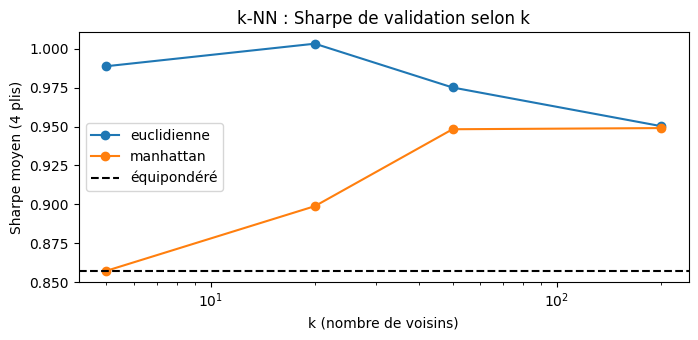

Réglage retenu : euclidienne, k = 20


In [12]:
CONFIGS["knn"] = {f"{nom}, k = {k}": dict(k=k, metric=metric)
                  for nom, metric in [("euclidienne", "euclidean"), ("manhattan", "cityblock")] for k in [5, 20, 50, 200]}
CV["knn"] = cross_validate("knn")

sharpe_val = CV["knn"].groupby("config", sort=False)["sharpe"].mean()      # Sharpe moyen des 4 plis
KNN_RETENU = sharpe_val.idxmax()                                           # réglage testé en partie 7

fig, ax = plt.subplots(figsize=(7, 3.5))
for nom, metric in [("euclidienne", "euclidean"), ("manhattan", "cityblock")]:
    configs = [c for c, cfg in CONFIGS["knn"].items() if cfg["metric"] == metric]
    ax.plot([CONFIGS["knn"][c]["k"] for c in configs], sharpe_val[configs], marker="o", label=nom)
ax.axhline(REF_CV.loc["Équipondéré", "sharpe"], color="k", ls="--", label="équipondéré")
ax.set_xscale("log"); ax.set_xlabel("k (nombre de voisins)"); ax.set_ylabel("Sharpe moyen (4 plis)")
ax.set_title("k-NN : Sharpe de validation selon k"); ax.legend(); plt.tight_layout(); plt.show()
print("Réglage retenu :", KNN_RETENU)

**Ce que donne la validation.** Ce n'est pas encore le verdict (il se fait sur le test, en partie 7) : on regarde si le réglage retenu est prometteur face aux deux références. Bat-il l'équipondéré (Sharpe) ? Imite-t-il l'oracle mieux que l'allocation moyenne (entropie croisée) ? À quel prix (turnover, nombre d'actifs détenus) ?

In [13]:
lignes = [KNN_RETENU, "Équipondéré", "Moyenne des cibles du train"]
colonnes = {"sharpe": "Sharpe", "ce": "Entropie croisée", "turnover_an": "Turnover / an", "n_eff": "Actifs effectifs"}
summary(CV["knn"]).loc[lignes, list(colonnes)].rename(columns=colonnes)

,Sharpe,Entropie croisée,Turnover / an,Actifs effectifs
"euclidienne, k = 20",1.003,7.967,4.602,5.058
Équipondéré,0.857,2.726,0.242,15.000
Moyenne des cibles du train,0.898,2.721,0.245,13.446


**Lecture.** En validation, le k-NN fait un peu mieux que l'équipondéré en Sharpe. Mais il imite très mal l'oracle (son entropie croisée est bien au-dessus de celle de l'allocation moyenne, car il met 0 % sur des actifs que l'oracle détient), et ce gain a un prix : un portefeuille concentré sur quelques actifs et renouvelé plusieurs fois par an.

**Pourquoi c'est fragile : un exemple.** Le 30/09/2025, la date la plus récente du test : d'où viennent les voisins, et que vaut l'allocation du k-NN face à celle de l'oracle ?

In [14]:
def voisins_knn(date, config=KNN_RETENU):
    """Voisins d'une date du test (pris dans le train final 2006–2019), allocation k-NN et allocation oracle."""
    cfg, tr, t = CONFIGS["knn"][config], FINAL[0], X.index.get_loc(date)
    Z = prepare(["tab"], tr)[0]                                     # même normalisation que fit_predict
    voisins = tr[np.argsort(cdist(Z[[t]], Z[tr], cfg["metric"])[0])[:cfg["k"]]]
    mois = pd.Series(X.index[voisins].strftime("%Y-%m")).value_counts().sort_index()
    print(f"Dates des {cfg['k']} voisins : " + ", ".join(f"{m} ({n})" for m, n in mois.items()))
    poids = pd.DataFrame({"k-NN": Yn[voisins].mean(0), "Oracle": Yn[t]}, index=ASSETS) * 100
    return poids[(poids > 3).any(axis=1)].T.round(1)                # actifs à plus de 3 % chez l'un ou l'autre

voisins_knn("2025-09-30")

Dates des 20 voisins : 2007-11 (1), 2007-12 (2), 2017-07 (2), 2017-08 (8), 2017-12 (2), 2019-05 (5)


,MC.PA,BN.PA,TTE.PA,VIE.PA,GLE.PA,AIR.PA,AI.PA,CAP.PA,CASH
k-NN,8.7,11.2,12.6,17.6,2.3,10.2,19.6,7.1,10.0
Oracle,22.3,14.7,17.6,0.0,32.5,0.0,0.0,9.9,0.0


**Ce qu'il faut retenir.**
1. **Les features contiennent un peu d'information** : à situation semblable, l'allocation passée aide légèrement (le k-NN bat l'équipondéré en validation).
2. **Recopier le passé est fragile** : les voisins sont souvent des jours consécutifs (chevauchement des cibles, partie 2), donc quelques épisodes de marché seulement, et l'allocation obtenue est concentrée, instable et loin de l'oracle.
3. **Quand le marché ne ressemble plus au passé, les voisins n'ont plus de sens**, comme le montre l'exemple de 2025.

Peut-on faire mieux qu'une copie du passé ? C'est l'objet des réseaux (parties 4 à 6). Le verdict se fait sur le test, en partie 7, avec tous les modèles.

## 4. Réseau dense (MLP)

**Principe.** Le réseau lit les 160 features de la date $t$ et sort directement 16 poids :
`160 → n1 (ReLU, dropout) → n2 (ReLU, dropout) → 16 → softmax`. Le softmax garantit un portefeuille valide (poids positifs, somme 1, CASH compris).

**Démarche de choix.** Avec une cinquantaine de trimestres indépendants, le risque principal est le surapprentissage. On compare donc peu de configurations, toutes petites : la taille des couches (64-32 ou 32-16), le dropout (0,2 ou 0,4), et la **perte** (entropie croisée ou Sharpe direct, avec des lots de 256 dates pour que le Sharpe du lot soit moins bruité).

In [15]:
class MLP(nn.Module):
    def __init__(self, n1=64, n2=32, dropout=0.2, n_in=160):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, n1), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(n1, n2), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(n2, 16))
    def forward(self, x):                                   # x : (B, 160)
        return torch.softmax(self.net(x), dim=-1)           # (B, 16)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print("Paramètres : 64-32 →", n_params(MLP(64, 32)), "| 32-16 →", n_params(MLP(32, 16)))

Paramètres : 64-32 → 12912 | 32-16 → 5952


In [16]:
mlp = lambda n1, n2, dropout, **kw: dict(model=MLP, params=dict(n1=n1, n2=n2, dropout=dropout), inputs=["tab"],
                                         **{**dict(lr=1e-4, wd=0, batch=64, max_epochs=200, patience=20), **kw})
CONFIGS["mlp"] = {"64-32, dropout 0,2": mlp(64, 32, 0.2),
                  "64-32, dropout 0,4": mlp(64, 32, 0.4),
                  "32-16, dropout 0,2": mlp(32, 16, 0.2),
                  "32-16, dropout 0,2, perte Sharpe": mlp(32, 16, 0.2, loss="sharpe", batch=256)}
CV["mlp"] = cross_validate("mlp")
summary(CV["mlp"])

,ce,ce_std,sharpe,turnover_an,n_eff,époques
"64-32, dropout 0,2",2.715,0.065,0.901,0.672,14.758,7.0
"64-32, dropout 0,4",2.717,0.063,0.903,0.626,14.784,14.0
"32-16, dropout 0,2",2.747,0.027,0.899,0.569,15.110,10.5
"32-16, dropout 0,2, perte Sharpe",2.844,0.160,0.900,0.545,14.547,4.5
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Lecture.** Les écarts d'entropie croisée entre configurations sont plus petits que leur dispersion entre plis (`ce_std`) : aucune taille ne se détache. À performance égale, on retient **le plus petit réseau (32-16, dropout 0,2), entraîné en entropie croisée**. La perte Sharpe ne donne pas un meilleur Sharpe hors échantillon : elle optimise une quantité très bruitée, et l'entropie croisée est conservée pour tous les modèles.

## 5. U-Net 1D

**Principe.** Le U-Net lit les **60 derniers rendements journaliers des 15 actions** comme un signal à 15 canaux. Un **encodeur** convolutif réduit la résolution temporelle (60 → 30 → 15 jours) pour capter les mouvements lents ; un **décodeur** la restaure, et des **connexions directes** (*skip connections*) lui redonnent le détail journalier perdu en chemin. La moyenne temporelle de la sortie passe dans une couche linéaire puis un softmax.

**Démarche de choix.** Le seul hyperparamètre comparé est la largeur `c` (nombre de filtres de la première couche, doublé à chaque niveau), qui fixe la capacité du réseau.

In [17]:
class UNet(nn.Module):
    def __init__(self, c=8, dropout=0.1):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv1d(i, o, 3, padding=1), nn.ReLU(), nn.Conv1d(o, o, 3, padding=1), nn.ReLU())
        self.enc1, self.enc2, self.mid = block(15, c), block(c, 2 * c), block(2 * c, 4 * c)
        self.pool = nn.MaxPool1d(2)
        self.up2, self.dec2 = nn.ConvTranspose1d(4 * c, 2 * c, 2, stride=2), block(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose1d(2 * c, c, 2, stride=2), block(2 * c, c)
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(c, 16)

    def forward(self, x):                                       # x : (B, 60 jours, 15 actions)
        e1 = self.enc1(x.transpose(1, 2))                       # (B, c, 60)
        e2 = self.enc2(self.pool(e1))                           # (B, 2c, 30)
        m = self.mid(self.pool(e2))                             # (B, 4c, 15)
        d2 = self.dec2(torch.cat([self.up2(m), e2], dim=1))     # (B, 2c, 30) : remontée + skip
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))    # (B, c, 60)
        return torch.softmax(self.head(self.drop(d1.mean(2))), dim=-1)

unet = lambda c: dict(model=UNet, params=dict(c=c), inputs=["seq_j"])
CONFIGS["unet"] = {"c = 4": unet(4), "c = 8": unet(8)}
print("Paramètres : c = 4 →", n_params(UNet(4)), "| c = 8 →", n_params(UNet(8)))
CV["unet"] = cross_validate("unet")
summary(CV["unet"])

Paramètres : c = 4 → 2880 | c = 8 → 10800


,ce,ce_std,sharpe,turnover_an,n_eff,époques
c = 4,2.704,0.074,0.922,0.384,14.404,8.0
c = 8,2.705,0.075,0.900,0.676,13.145,8.5
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Lecture.** L'entropie croisée se compare à la ligne « moyenne des cibles du train » : c'est le seuil en dessous duquel le réseau a extrait de l'information des 60 derniers jours. Les deux largeurs donnent des résultats voisins ; on retient **c = 8**.

## 6. Réseaux récurrents et attention : l'ordre des observations aide-t-il ?

Ici le réseau lit une **séquence** de rendements et la résume en un vecteur, d'où sortent les poids. Trois architectures, de la plus naïve à la plus structurée :

| | **V0 : LSTM global** | **V1 : LSTM partagé** | **V1T : Transformer partagé** |
|---|---|---|---|
| Ce que lit l'encodeur | 1 séquence : 60 jours × 15 actions | 15 séquences : 52 semaines × (action, CAC) | idem V1 |
| Encodeur | un LSTM pour tout le marché | **le même LSTM** appliqué à chaque action | une couche d'**auto-attention** appliquée à chaque action |
| Résumé de la séquence | dernier état caché | dernier état caché | **moyenne** sur les 52 semaines |
| Sortie | 16 scores → softmax | 1 score par action + 1 score CASH → softmax | idem V1 |

**Pourquoi partager l'encodeur ?** Dans V0, le réseau doit apprendre séparément le comportement de chaque action à partir de ~50 trimestres. Dans V1 et V1T, un seul petit encodeur apprend « comment noter une trajectoire », et il voit 15 fois plus d'exemples. Le softmax final met ensuite les 15 scores en concurrence.

**Démarche de choix.** Pour chaque architecture, une grille (LSTM ou GRU, taille de l'état 8/16/32, 1 ou 2 couches, dropout) a été explorée avec cette même validation croisée dans `Reccurent_protocole.ipynb`. On rejoue ici la meilleure configuration de chacune. Deux variantes n'ont rien apporté et ne sont pas reprises : ajouter les 160 features à la tête de sortie, et ajouter une attention entre les actions.

In [18]:
class V0(nn.Module):                                            # un LSTM lit les 15 actions ensemble
    def __init__(self, hidden=16, layers=2):
        super().__init__()
        self.rec, self.head = nn.LSTM(15, hidden, num_layers=layers, batch_first=True), nn.Linear(hidden, 16)
    def forward(self, x):                                       # x : (B, 60, 15)
        return torch.softmax(self.head(self.rec(x)[0][:, -1]), dim=-1)

class Shared(nn.Module):                                        # base de V1 et V1T : le même encodeur pour chaque action
    def forward(self, x):                                       # x : (B, 15, 52, 2)
        B, n, T, C = x.shape
        h = self.encode(x.reshape(B * n, T, C)).reshape(B, n, -1)       # un résumé par action : (B, 15, d)
        scores = torch.cat([self.score(h).squeeze(-1), self.cash(h.mean(1))], dim=-1)   # 15 actions + CASH
        return torch.softmax(scores, dim=-1)

class V1(Shared):                                               # encodeur LSTM, résumé = dernier état caché
    def __init__(self, hidden=16, layers=2):
        super().__init__()
        self.rec = nn.LSTM(2, hidden, num_layers=layers, batch_first=True)
        self.score, self.cash = nn.Linear(hidden, 1), nn.Linear(hidden, 1)
    def encode(self, s):
        return self.rec(s)[0][:, -1]

class V1T(Shared):                                              # encodeur Transformer, résumé = moyenne des 52 semaines
    def __init__(self, d=16, heads=2, ff=32, dropout=0.1):
        super().__init__()
        self.inp = nn.Linear(2, d)                              # chaque semaine → vecteur de taille d
        self.pos = nn.Parameter(0.02 * torch.randn(1, 52, d))   # position de la semaine (apprise)
        layer = nn.TransformerEncoderLayer(d, heads, ff, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.score, self.cash = nn.Linear(d, 1), nn.Linear(d, 1)
    def encode(self, s):
        return self.enc(self.inp(s) + self.pos).mean(1)         # chaque semaine regarde toutes les autres

CONFIGS["rec"] = {"V0 : LSTM global": dict(model=V0, params=dict(hidden=16, layers=2), inputs=["seq_j"]),
                  "V1 : LSTM partagé": dict(model=V1, params=dict(hidden=16, layers=2), inputs=["seq_h"]),
                  "V1T : Transformer, d = 8": dict(model=V1T, params=dict(d=8), inputs=["seq_h"]),
                  "V1T : Transformer, d = 16": dict(model=V1T, params=dict(d=16), inputs=["seq_h"])}
print("Paramètres :", {k: n_params(c["model"](**c["params"])) for k, c in CONFIGS["rec"].items()})
CV["rec"] = cross_validate("rec")
summary(CV["rec"])

Paramètres : {'V0 : LSTM global': 4560, 'V1 : LSTM partagé': 3490, 'V1T : Transformer, d = 8': 1330, 'V1T : Transformer, d = 16': 3138}


,ce,ce_std,sharpe,turnover_an,n_eff,époques
V0 : LSTM global,2.681,0.080,0.963,0.416,14.512,2.0
V1 : LSTM partagé,2.716,0.043,0.875,0.826,14.970,7.0
"V1T : Transformer, d = 8",2.716,0.035,0.854,0.515,15.177,11.0
"V1T : Transformer, d = 16",2.691,0.042,0.906,0.857,14.458,8.5
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Lecture.**
- **V0** s'arrête après très peu d'époques : il reste proche de l'allocation moyenne et n'exploite pas vraiment la séquence.
- **Le Transformer partagé (V1T, d = 16)** est le modèle séquentiel qui imite le mieux l'oracle, avec une dispersion entre plis plus faible que V0. C'est la configuration retenue.
- Notre interprétation : l'oracle dépend surtout de statistiques calculées sur **toute** la fenêtre (volatilité, corrélation au marché). La moyenne sur les 52 semaines du Transformer les capte directement, alors que le dernier état d'un LSTM privilégie le passé récent.

## 7. Backtest sur 2020–2025

Le meilleur modèle de chaque famille est **réentraîné sur 2006–2019** (nombre d'époques fixé par la validation croisée, moyenne de 3 graines), puis évalué **une seule fois** sur le test. Il est comparé à :
- l'**équipondéré** : la référence à battre ;
- le **Markowitz glissant 63 jours** : on détient l'allocation qui *était* optimale sur les 63 derniers jours, c'est-à-dire la dernière allocation oracle connue ;
- le **Markowitz glissant 252 jours** : même optimisation sur un an d'historique ;
- l'**oracle** : le plafond.

In [19]:
RETENUS = {"k-NN": ("knn", KNN_RETENU), "MLP": ("mlp", "32-16, dropout 0,2"),
           "U-Net": ("unet", "c = 8"), "Transformer V1T": ("rec", "V1T : Transformer, d = 16"),
           "LSTM global V0": ("rec", "V0 : LSTM global")}       # V0 : ajouté en contrôle (meilleure entropie croisée en validation)

f = RES / "poids_test.npz"
W_test = dict(np.load(f)) if f.exists() and not RERUN else {}
for nom, (fam, conf) in RETENUS.items():
    if nom not in W_test:                                       # seuls les modèles absents du cache sont entraînés
        epochs = max(1, int(CV[fam].loc[CV[fam]["config"] == conf, "époques"].median()))      # fixé par la validation croisée
        W_test[nom] = np.mean([fit_predict(CONFIGS[fam][conf], *FINAL, epochs=epochs, seed=s)[0] for s in range(3)], axis=0)
        print(nom, "| époques :", epochs, flush=True)
np.savez(f, **W_test)
W_test = {nom: W_test[nom] for nom in RETENUS}

In [20]:
te = FINAL[1]
f = RES / "markowitz_252.npy"
if f.exists() and not RERUN:
    W_roll = np.load(f)
else:                                                  # Markowitz estimé sur les 252 derniers jours, à chaque date du test
    W_roll = np.array([max_sharpe(R_day[p - 251:p + 1, :15], rf_day[p - 251:p + 1]) for p in pos[te]])
    np.save(f, W_roll)

W_all = {**W_test,
         "Équipondéré": np.tile(EW, (len(te), 1)),
         "Markowitz glissant 63 j": Yn[te - N],        # la cible de t−63 ne dépend que de rendements connus en t
         "Markowitz glissant 252 j": W_roll,
         "Oracle": Yn[te]}
results = {nom: evaluate(W, te) for nom, W in W_all.items()}
table = pd.DataFrame({nom: stats for nom, (stats, _) in results.items()}).T
table.round(3)

,ce,sharpe,sharpe_std,rdt_ann,perte_max,turnover_an,n_eff
k-NN,7.152,0.576,0.113,0.123,-0.419,4.396,5.784
MLP,2.778,0.549,0.024,0.106,-0.371,0.703,14.741
U-Net,2.817,0.520,0.013,0.098,-0.360,0.637,13.141
Transformer V1T,2.692,0.582,0.034,0.108,-0.351,1.014,12.788
LSTM global V0,2.789,0.530,0.007,0.100,-0.363,0.301,14.596
Équipondéré,2.921,0.570,0.007,0.115,-0.382,0.302,15.000
Markowitz glissant 63 j,12.683,0.278,0.158,0.051,-0.433,6.351,3.303
Markowitz glissant 252 j,12.702,0.367,0.068,0.071,-0.378,3.693,3.255
Oracle,1.225,3.288,0.232,0.757,-0.166,6.335,3.371


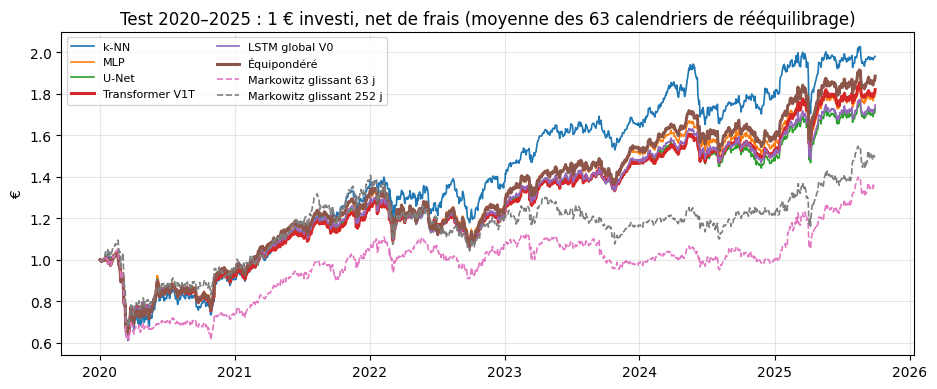

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for nom, (_, wealth) in results.items():
    if nom != "Oracle":
        ax.plot(wealth, lw=2.2 if nom in ("Équipondéré", "Transformer V1T") else 1.2, ls="--" if "Markowitz" in nom else "-", label=nom)
ax.set_title("Test 2020–2025 : 1 € investi, net de frais (moyenne des 63 calendriers de rééquilibrage)")
ax.set_ylabel("€"); ax.grid(alpha=0.3); ax.legend(ncol=2, fontsize=8); plt.show()

### Régularité des allocations

Un bon modèle ne doit pas seulement performer : il doit proposer des portefeuilles **stables**, sinon les frais mangent la performance. On compare les poids de l'oracle, du Markowitz glissant et du réseau retenu sur le test.

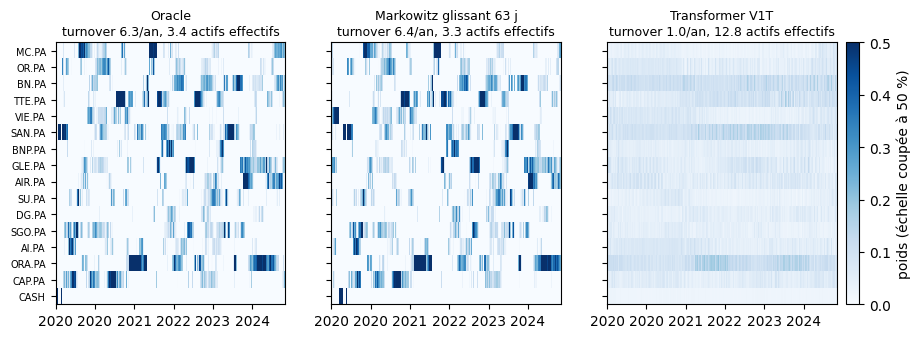

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, nom in zip(axes, ["Oracle", "Markowitz glissant 63 j", "Transformer V1T"]):
    im = ax.imshow(W_all[nom].T, aspect="auto", cmap="Blues", vmin=0, vmax=0.5, interpolation="nearest")
    ax.set_title(f"{nom}\nturnover {table.loc[nom, 'turnover_an']:.1f}/an, {table.loc[nom, 'n_eff']:.1f} actifs effectifs", fontsize=9)
    ax.set_xticks(np.arange(0, len(te), 252), X.index[te][::252].year)
axes[0].set_yticks(range(16), ASSETS, fontsize=7)
fig.colorbar(im, ax=axes, label="poids (échelle coupée à 50 %)", pad=0.01); plt.show()

**Lecture.**
- **L'oracle est hors d'atteinte** : son Sharpe est sans commune mesure avec le reste. Il existe une excellente allocation chaque trimestre, mais elle dépend des rendements futurs.
- **Recopier l'ancienne allocation optimale ne marche pas** : le Markowitz glissant est concentré, très instable, et ne bat pas l'équipondéré. L'allocation optimale d'un trimestre ne dit presque rien de la suivante : c'est l'erreur d'estimation classique de Markowitz.
- **Les réseaux apprennent la prudence** : ils sortent des portefeuilles diversifiés et réguliers (turnover faible, nombre effectif d'actifs élevé), légèrement inclinés par rapport à l'équipondéré. Leur Sharpe est du même ordre que celui de l'équipondéré : sur 6 ans de test, un Sharpe n'est mesuré qu'à environ ±0,4 près, bien plus que les écarts entre stratégies.
- **Le Transformer partagé est celui qui imite le mieux l'oracle** (entropie croisée la plus basse) : c'est lui que l'on interprète.

## 8. Que regarde le modèle ? Analyse SHAP du Transformer

Dans V1T, le score d'une action ne dépend que de **sa propre séquence** (52 semaines × 2 canaux) ; le softmax ne fait ensuite que comparer les scores. On explique donc la fonction « séquence d'une action → score », avec `shap.GradientExplainer` : chaque valeur SHAP mesure de combien un rendement hebdomadaire donné fait monter ou baisser le score de l'action, par rapport à une séquence de référence tirée du train.

In [23]:
import shap

fam, conf = RETENUS["Transformer V1T"]
epochs = max(1, int(CV[fam].loc[CV[fam]["config"] == conf, "époques"].median()))
model, xs, _ = train(CONFIGS[fam][conf], FINAL[0], epochs=epochs, seed=0)

class ActionScore(nn.Module):                           # séquence d'une action (n, 52, 2) → son score avant softmax
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, s):
        return self.m.score(self.m.encode(s))

def sample(i, n):                                       # n séquences (date, action) tirées au hasard parmi les dates i
    s = xs[0][i].reshape(-1, 52, 2)
    return s[torch.randperm(len(s))[:n]]

torch.manual_seed(0); np.random.seed(0)                # tirages de sample() et de GradientExplainer reproductibles
f = ActionScore(model).eval()
background, explained = sample(FINAL[0], 200), sample(FINAL[1], 1000)        # référence : train ; à expliquer : test
sv = np.squeeze(np.array(shap.GradientExplainer(f, background).shap_values(explained)))   # (1000, 52, 2)
xe = explained.numpy()

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


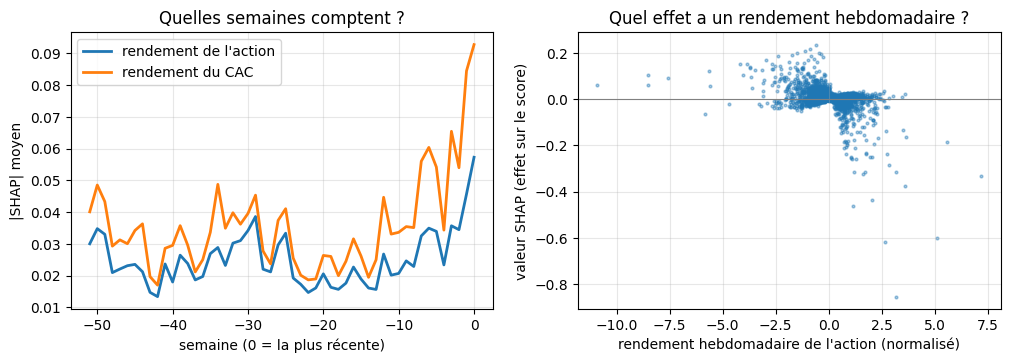

Corrélation du score avec la volatilité de l'action sur 1 an : -0.20
Corrélation du score avec sa performance sur 1 an            : -0.09
Part de l'importance SHAP portée par le canal CAC             : 59%


In [24]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.6))
for c, nom in enumerate(["rendement de l'action", "rendement du CAC"]):
    a.plot(np.arange(-51, 1), np.abs(sv[..., c]).mean(0), lw=2, label=nom)
a.set_title("Quelles semaines comptent ?"); a.set_xlabel("semaine (0 = la plus récente)"); a.set_ylabel("|SHAP| moyen"); a.legend(); a.grid(alpha=0.3)
b.scatter(xe[..., 0].ravel()[::20], sv[..., 0].ravel()[::20], s=4, alpha=0.4)
b.axhline(0, color="gray", lw=0.8); b.set_title("Quel effet a un rendement hebdomadaire ?")
b.set_xlabel("rendement hebdomadaire de l'action (normalisé)"); b.set_ylabel("valeur SHAP (effet sur le score)"); b.grid(alpha=0.3)
plt.show()

# lien entre le score d'une action et deux statistiques simples de sa trajectoire
with torch.no_grad():
    score = f(explained).squeeze(-1).numpy()
print(f"Corrélation du score avec la volatilité de l'action sur 1 an : {np.corrcoef(score, xe[..., 0].std(1))[0, 1]:+.2f}")
print(f"Corrélation du score avec sa performance sur 1 an            : {np.corrcoef(score, xe[..., 0].sum(1))[0, 1]:+.2f}")
print(f"Part de l'importance SHAP portée par le canal CAC             : {np.abs(sv[..., 1]).sum() / np.abs(sv).sum():.0%}")

**Lecture.**
- **Graphique de gauche** : l'importance est concentrée sur les 2 à 3 dernières semaines (la plus récente pèse environ 4 à 5 fois le minimum), mais elle ne s'annule jamais : le modèle lit toute l'année, avec un poids plus fort sur le récent. Les pics isolés viennent de quelques semaines extrêmes de l'échantillon, pas d'une saisonnalité. Le canal **CAC** domine (59 % de l'importance, au-dessus de l'action presque chaque semaine) : le modèle regarde d'abord le régime de marché, puis la trajectoire de l'action.
- **Graphique de droite** : la relation est **décroissante et asymétrique**, sans forme en U. Les fortes hausses hebdomadaires (au-delà de +1 écart-type) font nettement baisser le score (jusqu'à −0,85), alors que les baisses l'affectent peu, voire le relèvent légèrement. Le modèle ne récompense donc pas le momentum : il **pénalise les actions qui viennent de bondir**.
- **Les corrélations** confirment une règle réelle mais faible : score et volatilité à 1 an **−0,20**, score et performance à 1 an **−0,09** (quasi nul).

Le réseau note donc les actions sur leur **profil de risque récent** et n'essaie pas de deviner les gagnants : le risque est persistant, les rendements ne le sont pas. C'est cohérent avec des portefeuilles diversifiés, légèrement inclinés vers les actions peu volatiles, et un Sharpe proche de l'équipondéré. Cette lecture décrit ce que le modèle utilise (1 000 séquences du test, une seule graine), pas une vérité de marché.


## 9. Conclusion

**Ce que nous avons fait.** Un jeu de données contrôlé (160 features, cible oracle à 63 jours, aucune fuite du futur), un protocole unique (validation croisée walk-forward purgée, test final utilisé une seule fois, backtest avec frais), et quatre approches comparées sur la même base : k-NN, MLP, U-Net, réseaux séquentiels.

**Ce que nous trouvons.**
1. **L'oracle est très difficile à imiter.** Il est concentré, change presque entièrement d'un trimestre à l'autre, et dépend des rendements futurs. La meilleure prédiction au sens de l'entropie croisée reste proche de l'allocation moyenne : tous les réseaux sortent des portefeuilles diversifiés.
2. **L'architecture compte plus que la quantité d'information.** Partager un même encodeur entre les actions, et résumer toute l'année plutôt que les derniers jours, améliore l'imitation de l'oracle. Ajouter des features ou de la capacité ne change rien.
3. **Mieux imiter l'oracle ne suffit pas à battre l'équipondéré.** Les Sharpe des réseaux et de l'équipondéré sont du même ordre, et leurs écarts sont inférieurs à l'incertitude de mesure. C'est le résultat classique de DeMiguel, Garlappi et Uppal (2009) : l'erreur d'estimation coûte ce que l'optimisation rapporte.
4. **Les réseaux font nettement mieux que le Markowitz « naïf »** (glissant) et que le k-NN en régularité : peu de transactions, pas de concentration extrême.
5. **Ce que le modèle apprend est interprétable** : il note les actions sur leur profil de risque passé, la seule partie réellement persistante du problème.

**Limites et pistes.** Une cinquantaine de trimestres indépendants seulement, 15 actions, un seul échantillon de test de 6 ans. Pistes : une cible plus prévisible (portefeuille de variance minimale), un mélange équipondéré / modèle, un univers plus large pour multiplier les exemples vus par l'encodeur partagé.